In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
%matplotlib inline


#1 读取文件信息
file_path = r"D:\ESE5023\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"
ds = xr.open_dataset(file_path)
ds

<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (time, lat, lon) float32 2MB ...
    column_averaging_kernel  (time, pressure, lat, lon) float32 22MB ...
    vmr_profile_ch4_apriori  (time, pressure, lat, lon) float32 22MB ...
Attributes: (12/28)
    activity_id:            obs4MIPs
    comment:                Since long time, climate modellers use ensemble a...
    contact:                Maximilian Reuter (maximilian.reuter@iup.physik.u...
    Conventions:            CF-1.7 ODS-2.1
    creation_date:          2021-02-05T09:48:47Z
    data_specs_version:     2.1.0
    ...                     ...
    source_version_number:  v4.3
    title:                  C3S XCH4 v4.3
    tracking_id:            892d184a-7b35-4bba-836a-94b9cfeb360e
    variable_id:            xch4
    variant_info:           Best Estimate
    variant_label:          BE

In [2]:
#1. 提取甲烷数据
ch4 = ds["xch4"]
print(ch4)

<xarray.DataArray 'xch4' (time: 210, lat: 36, lon: 72)> Size: 2MB
[544320 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 ... 2020-06-16
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B -177.5 -172.5 -167.5 ... 167.5 172.5 177.5
Attributes:
    standard_name:  dry_atmosphere_mole_fraction_of_methane
    long_name:      column-average dry-air mole fraction of atmospheric methane
    units:          1
    cell_methods:   time: mean
    fill_value:     1e+20
    comment:        Satellite retrieved column-average dry-air mole fraction ...


In [3]:
# 将无效数据和填充值转换为 NaN
ch4_clean = ch4.where(np.isfinite(ch4) & (ch4 < 1e10))

#转换单位为ppb
ch4_ppb = ch4_clean * 1e9
ch4_ppb.attrs["units"] = "ppb"


print(ch4_ppb)

<xarray.DataArray 'xch4' (time: 210, lat: 36, lon: 72)> Size: 2MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., n

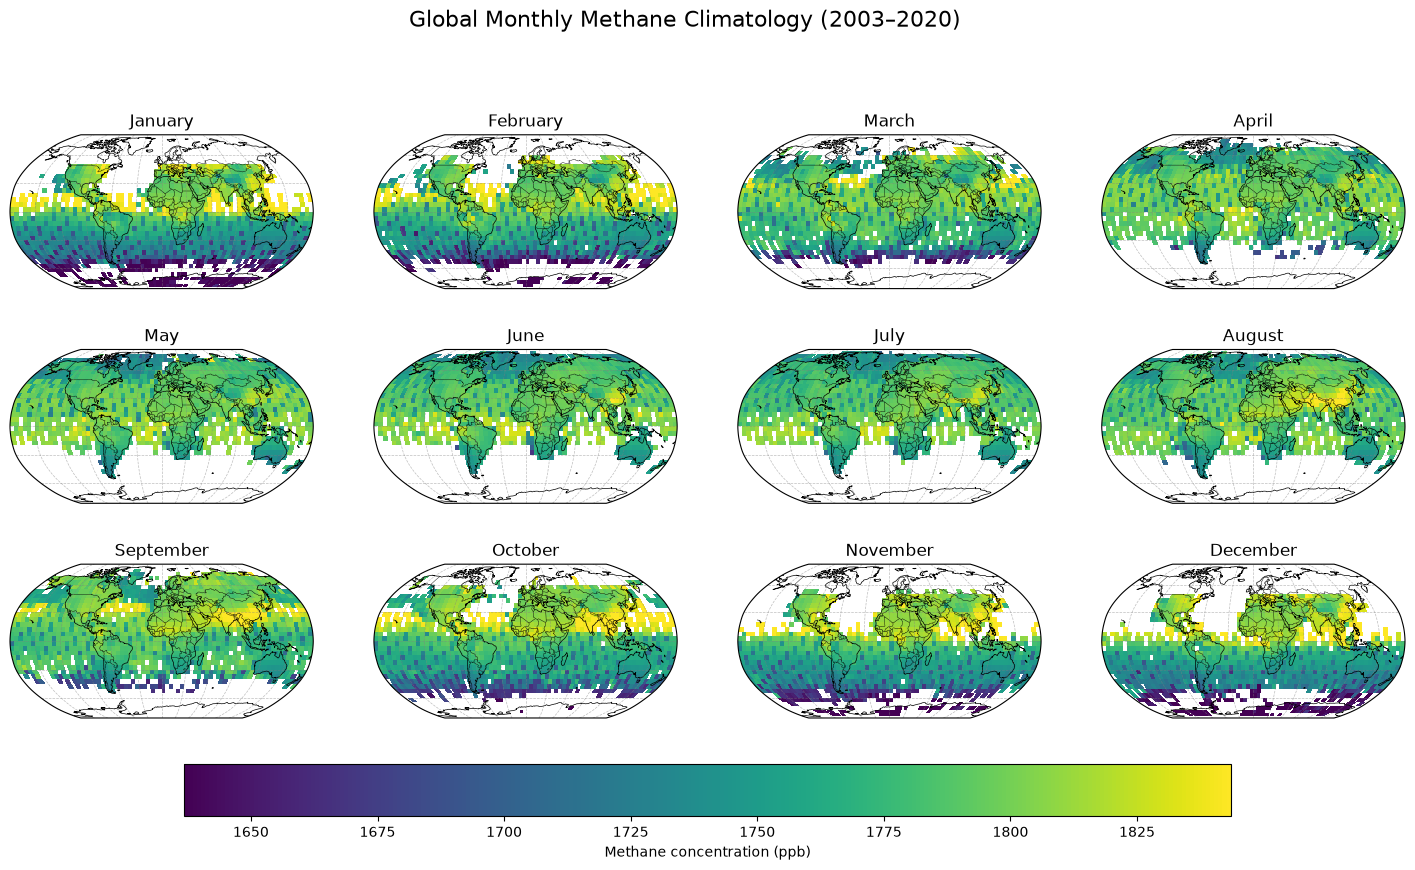

In [4]:
# 1.1 计算气候态
climatology = ch4_ppb.groupby("time.month").mean(dim="time",)
#1.1气候态结果图
month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]


lon = climatology.lon
lat = climatology.lat
vmin, vmax = np.nanpercentile(climatology.values, [2, 98])

fig, axes = plt.subplots(
    3, 4, figsize=(18, 10),
    subplot_kw={"projection": ccrs.Robinson()}
)

# 绘制12个月的气候态结果图
for i, ax in enumerate(axes.flat):

    im = ax.pcolormesh(
        lon, lat, climatology.sel(month=i+1),
        transform=ccrs.PlateCarree(),
        cmap="viridis", vmin=vmin, vmax=vmax,
        shading="auto"
    )

    ax.set_global()
    ax.coastlines(linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        linewidth=0.5, color="gray",
        alpha=0.5, linestyle="--"
    )
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 30))

    ax.set_title(month_names[i])


cbar = fig.colorbar(
    im, ax=axes.ravel().tolist(),
    orientation="horizontal", pad=0.06,
    shrink=0.75
)
cbar.set_label("Methane concentration (ppb)")
fig.suptitle("Global Monthly Methane Climatology (2003–2020)", fontsize=16)
plt.show()

In [5]:
#1.2
#计算权重
weights = np.cos(np.deg2rad(ch4_ppb["lat"]))
global_ch4 = ch4_ppb.weighted(weights).mean(dim=("lat", "lon"),)

print(global_ch4)

<xarray.DataArray 'xch4' (time: 210)> Size: 2kB
array([1713.49139949, 1719.92258196, 1733.51969734, 1741.75989025,
       1743.96019217, 1742.9729384 , 1745.33766449, 1751.44989244,
       1749.33122929, 1736.69786687, 1725.54902848, 1720.73877732,
       1712.14989303, 1721.31922389, 1734.21696401, 1742.69156058,
       1742.19190561, 1744.34731695, 1744.86202533, 1748.20243246,
       1747.19370063, 1736.42159882, 1726.23678054, 1722.66895711,
       1717.89884968, 1724.99139444, 1736.46319431, 1743.95731199,
       1747.27492667, 1747.21798719, 1745.53864271, 1749.20921664,
       1751.61246948, 1739.70947221, 1749.01717181, 1742.50406944,
       1741.97405441, 1735.54960511, 1734.91747187, 1741.63596122,
       1749.59818772, 1749.87683157, 1754.65085402, 1757.66751662,
       1755.00692358, 1755.05138001, 1754.14885375, 1750.79010476,
       1750.31263013, 1743.26036816, 1748.08683102, 1749.77185635,
       1750.14281217, 1751.67632611, 1757.21801887, 1762.33249918,
       1761.94

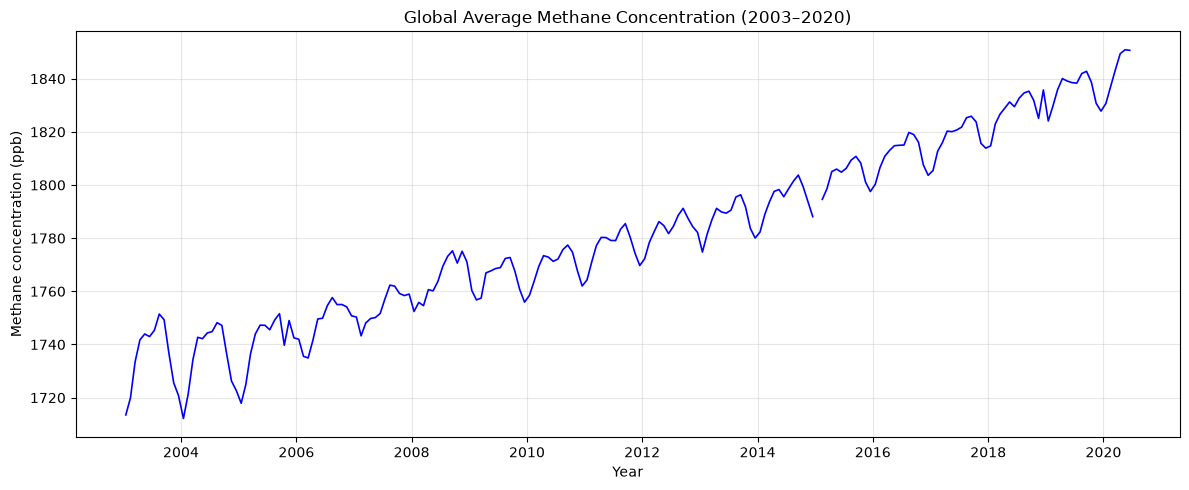

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    global_ch4.time,
    global_ch4,
    color="blue",
    linewidth=1.2
)
plt.xlabel("Year")
plt.ylabel("Methane concentration (ppb)")
plt.title("Global Average Methane Concentration (2003–2020)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

有效月份数： 96


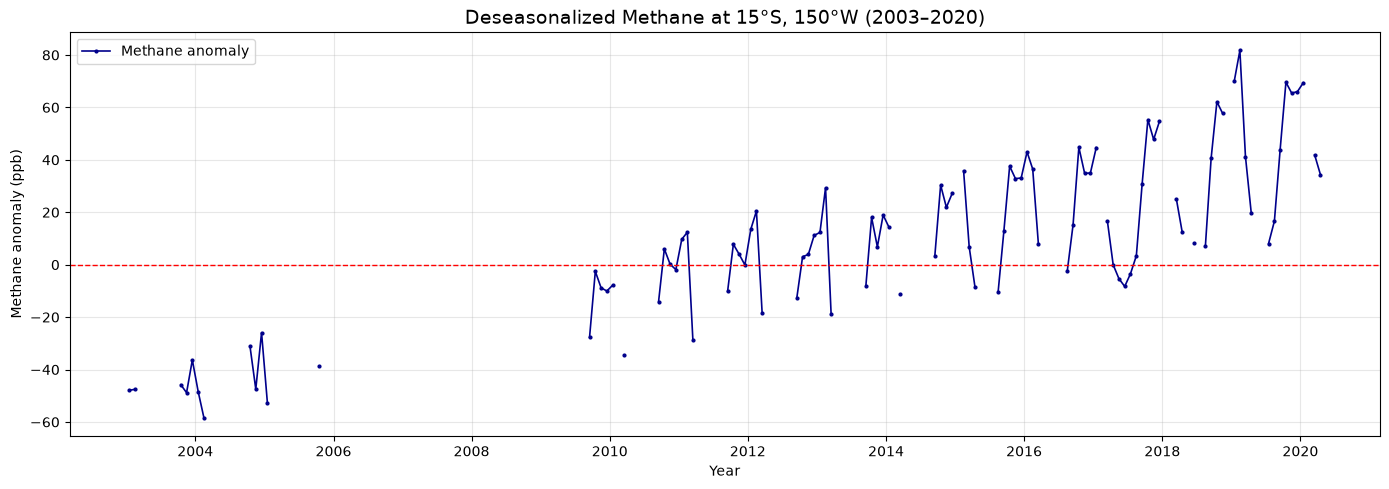

In [7]:

# 1.3提取目标位置附近的 5° × 5° 网格
nearby = ch4_ppb.sel(lat=slice(-17.5, -12.5), lon=slice(-152.5, -147.5))
valid_grid_count = nearby.count(dim=["lat", "lon"])
point_ch4 = nearby.mean(dim=["lat", "lon"],skipna=True)

# 至少有2个有效网格才保留
point_ch4 = point_ch4.where(valid_grid_count >= 2)

#使用第一步计算的全球气候态数据
point_clim = climatology.sel(
    lat=slice(-17.5, -12.5),
    lon=slice(-152.5, -147.5)
).mean(dim=["lat", "lon"], skipna=True)

#去季节化
point_anomaly = (
    point_ch4.groupby("time.month") - point_clim
)

# 统计有效月份
print("有效月份数：", int(point_anomaly.count()))

#绘图
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    point_anomaly.time,
    point_anomaly,
    color="darkblue",
    linewidth=1.2,
    marker="o",
    markersize=2,
    label="Methane anomaly"
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Deseasonalized Methane at 15°S, 150°W (2003–2020)",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Methane anomaly (ppb)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
#2读取文件信息
file_path = r"D:\ESE5023\NOAA_NCDC_ERSST_v3b_SST.nc"
ds = xr.open_dataset(file_path)
ds

<xarray.Dataset> Size: 44MB
Dimensions:  (time: 684, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 44MB ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...

In [9]:
#提取 SST 变量
sst = ds["sst"]
#提取 Niño 3.4 区域
nino34 = sst.sel(lat=slice(-5, 5),lon=slice(190, 240))
print(nino34)

<xarray.DataArray 'sst' (time: 684, lat: 5, lon: 26)> Size: 356kB
[88920 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 20B -4.0 -2.0 0.0 2.0 4.0
  * lon      (lon) float32 104B 190.0 192.0 194.0 196.0 ... 236.0 238.0 240.0
Attributes:
    pointwidth:          1.0
    valid_min:           -3.0
    valid_max:           45.0
    units:               degree_Celsius
    long_name:           Extended reconstructed sea surface temperature
    standard_name:       sea_surface_temperature
    iridl:hasSemantics:  iridl:SeaSurfaceTemperature


In [17]:
# 2.1
# 计算权重和SST
weights = np.cos(np.deg2rad(nino34.lat))
nino34_sst = nino34.weighted(weights).mean(dim=("lat", "lon"))
# 计算月气候态
nino34_climatology = nino34_sst.groupby("time.month").mean(dim="time")
df = nino34_climatology.to_dataframe(name='SST (°C)')
print(df)

        SST (°C)
month           
1      26.567789
2      26.742273
3      27.239603
4      27.693741
5      27.795214
6      27.597757
7      27.198917
8      26.824203
9      26.737827
10     26.717142
11     26.693287
12     26.613092


In [11]:
# 计算异常值 
nino34_anomaly = (nino34_sst.groupby("time.month") - nino34_climatology)
print(nino34_anomaly)

<xarray.DataArray 'sst' (time: 684)> Size: 3kB
array([-3.19671631e-01, -4.68568802e-01, -2.68173218e-01, -1.87025070e-01,
       -1.77633286e-01, -3.57751846e-01, -1.42024994e-01,  1.46160126e-02,
       -1.52326584e-01, -3.79961014e-01, -3.60948563e-01, -2.08705902e-01,
       -1.91469193e-01, -1.34254456e-01, -2.40343094e-01, -1.85152054e-01,
        5.19752502e-02,  2.39465714e-01, -7.02838898e-02, -4.18712616e-01,
       -7.78390884e-01, -7.92451859e-01, -4.96280670e-01, -4.17322159e-01,
       -4.44835663e-01, -4.56037521e-01, -4.36143875e-01, -4.66995239e-01,
       -5.64611435e-01, -4.26933289e-01, -2.76754379e-01, -3.17255020e-01,
       -6.73257828e-01, -6.66168213e-01, -8.17825317e-01, -8.65585327e-01,
       -7.01501846e-01, -3.57101440e-01,  6.96544647e-02,  1.73439026e-01,
       -9.07344818e-02,  7.68814087e-02,  6.87768936e-01,  7.95410156e-01,
        7.13079453e-01,  8.34375381e-01,  9.08702850e-01,  1.08613205e+00,
        8.51739883e-01,  5.23542404e-01, -1.30517960e

In [12]:
#2.2
# 计算3个月滑动平均
nino34_index = nino34_anomaly.rolling(time=3,center=True).mean()
print(nino34_index)

<xarray.DataArray 'sst' (time: 684)> Size: 3kB
array([            nan, -3.52137893e-01, -3.07922363e-01, -2.10943863e-01,
       -2.40803406e-01, -2.25803375e-01, -1.61720276e-01, -9.32451859e-02,
       -1.72557190e-01, -2.97745377e-01, -3.16538483e-01, -2.53707886e-01,
       -1.78143188e-01, -1.88688919e-01, -1.86583206e-01, -1.24506630e-01,
        3.54296379e-02,  7.37190247e-02, -8.31769332e-02, -4.22462463e-01,
       -6.63185120e-01, -6.89041138e-01, -5.68684876e-01, -4.52812821e-01,
       -4.39398438e-01, -4.45672363e-01, -4.53058869e-01, -4.89250183e-01,
       -4.86179978e-01, -4.22766358e-01, -3.40314239e-01, -4.22422409e-01,
       -5.52227020e-01, -7.19083786e-01, -7.83192933e-01, -7.94970810e-01,
       -6.41396224e-01, -3.29649597e-01, -3.80026512e-02,  5.07863350e-02,
        5.31953163e-02,  2.24638626e-01,  5.20020187e-01,  7.32086182e-01,
        7.80955017e-01,  8.18719208e-01,  9.43070114e-01,  9.48858261e-01,
        8.20471466e-01,  4.14921433e-01, -8.05009231e

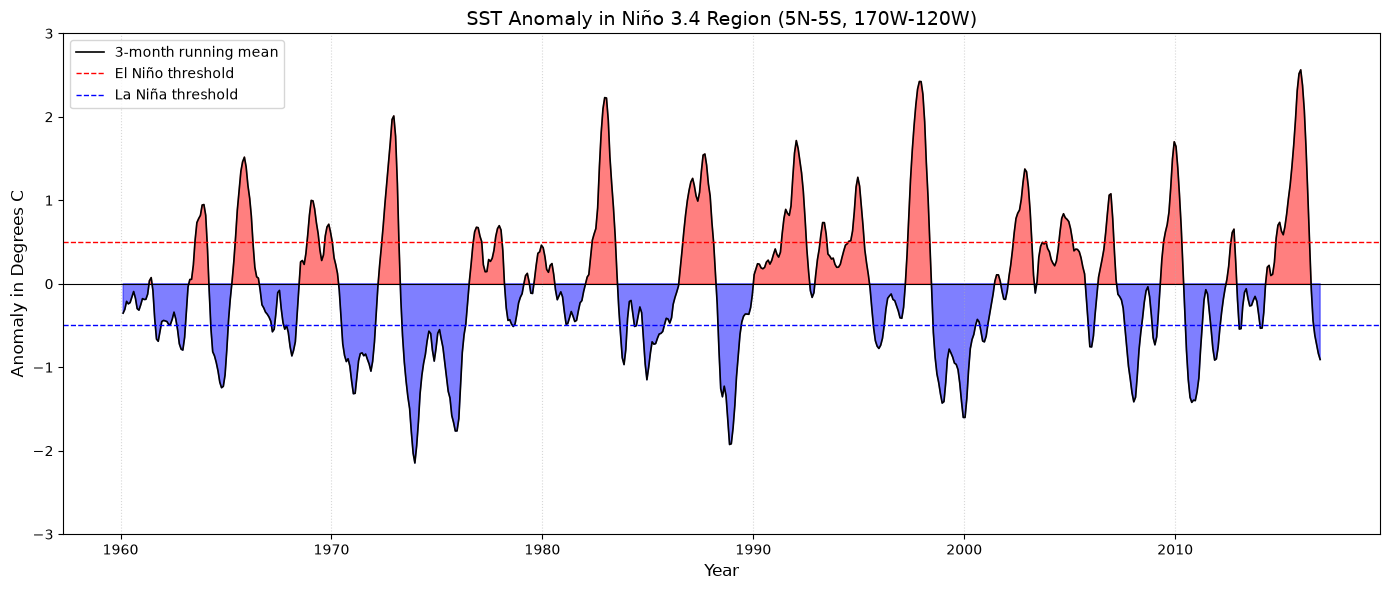

In [14]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.fill_between(nino34_index.time, 0, nino34_index, where=(nino34_index >= 0), color="red", alpha=0.5, interpolate=True)
ax.fill_between(nino34_index.time, 0, nino34_index, where=(nino34_index < 0), color="blue", alpha=0.5, interpolate=True)
ax.plot(nino34_index.time, nino34_index, color="black", linewidth=1.2, label="3-month running mean")

#画阈值线和零线
ax.axhline(0.5, color="red", linestyle="--", linewidth=1, label="El Niño threshold")
ax.axhline(-0.5, color="blue", linestyle="--", linewidth=1, label="La Niña threshold")
ax.axhline(0, color="black", linewidth=0.8)

#设置轴范围和标签
ax.set_ylim(-3, 3)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Anomaly in Degrees C", fontsize=12) # 修正了原代码引号的小错误
ax.set_title("SST Anomaly in Niño 3.4 Region (5N-5S, 170W-120W)", fontsize=14)

ax.legend(loc="best")
ax.grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

In [18]:
#3 读取PACE叶绿素数据
from pathlib import Path
import re

folder_path = Path(r"D:\pace l3 chla")

#只读取0.1度数据，避免和4 km数据重复
file_list = sorted(folder_path.glob("*chlor_a.0p1deg.nc"))
print("文件数量：", len(file_list))
print("第一个文件：", file_list[0].name)
print("最后一个文件：", file_list[-1].name)


文件数量： 29
第一个文件： PACE_OCI.20240401_20240430.L3m.MO.CHL.V3_2.chlor_a.0p1deg.nc
最后一个文件： PACE_OCI.20260801_20260831.L3m.MO.CHL.V3_2.chlor_a.0p1deg.nc


In [19]:
#3.1 计算南海区域月平均叶绿素
time_list = []
chla_mean_list = []
map_list = []

for file in file_list:
    ds_pace = xr.open_dataset(file)
    chla = ds_pace["chlor_a"]

    #从文件名提取日期
    date_text = re.search(r"(\d{8})_", file.name).group(1)
    date = pd.to_datetime(date_text)

    #提取南海区域 5°N-25°N，105°E-121°E
    south_china_sea = chla.sel(lat=slice(25, 5), lon=slice(105, 121))

    #叶绿素分布偏斜，先取对数再计算几何平均
    log_chla = np.log(south_china_sea.where(south_china_sea > 0))
    weights = np.cos(np.deg2rad(south_china_sea.lat))
    chla_mean = np.exp(
        log_chla.weighted(weights).mean(dim=("lat", "lon"), skipna=True)
    )

    #地图降采样到约1度，减少内存占用
    map_data = chla.isel(lat=slice(None, None, 10), lon=slice(None, None, 10))
    map_data = map_data.expand_dims(time=[date]).load()

    time_list.append(date)
    chla_mean_list.append(float(chla_mean))
    map_list.append(map_data)
    ds_pace.close()

#转换为时间序列和三维数组
chla_series = xr.DataArray(
    chla_mean_list,
    coords={"time": pd.DatetimeIndex(time_list)},
    dims="time",
    name="chlor_a"
)

chla_maps = xr.concat(map_list, dim="time")
print(chla_series)


<xarray.DataArray 'chlor_a' (time: 29)> Size: 232B
array([0.1340947 , 0.12448823, 0.14188859, 0.16051087, 0.17143136,
       0.18680483, 0.19307011, 0.22016862, 0.29933897, 0.37597281,
       0.30133161, 0.21790379, 0.15667145, 0.13455231, 0.16277966,
       0.19016813, 0.19366883, 0.19682308, 0.20367284, 0.27050909,
       0.30373001, 0.30818754, 0.23955372, 0.20052233, 0.14741191,
       0.13514672, 0.14353786, 0.16047452, 0.18557613])
Coordinates:
  * time     (time) datetime64[us] 232B 2024-04-01 2024-05-01 ... 2026-08-01


In [20]:
#计算月气候态和去季节序列
chla_climatology = chla_series.groupby("time.month").mean(dim="time")
chla_anomaly = chla_series.groupby("time.month") - chla_climatology

print("月气候态：")
print(chla_climatology)
print("去季节序列：")
print(chla_anomaly)


月气候态：
<xarray.DataArray 'chlor_a' (month: 12)> Size: 96B
array([0.34208018, 0.27044266, 0.20921306, 0.14605935, 0.13139576,
       0.14940204, 0.17038451, 0.18355877, 0.19181395, 0.19837148,
       0.24533886, 0.30153449])
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
去季节序列：
<xarray.DataArray 'chlor_a' (time: 29)> Size: 232B
array([-0.01196465, -0.00690752, -0.00751345, -0.00987364, -0.01212741,
       -0.00500912, -0.00530136, -0.02517024, -0.00219552,  0.03389263,
        0.03088894,  0.00869073,  0.0106121 ,  0.00315656,  0.01337762,
        0.01978362,  0.01011006,  0.00500912,  0.00530136,  0.02517024,
        0.00219552, -0.03389263, -0.03088894, -0.00869073,  0.00135256,
        0.00375096, -0.00586417, -0.00990998,  0.00201735])
Coordinates:
  * time     (time) datetime64[us] 232B 2024-04-01 2024-05-01 ... 2026-08-01
    month    (time) int64 232B 4 5 6 7 8 9 10 11 12 1 ... 11 12 1 2 3 4 5 6 7 8


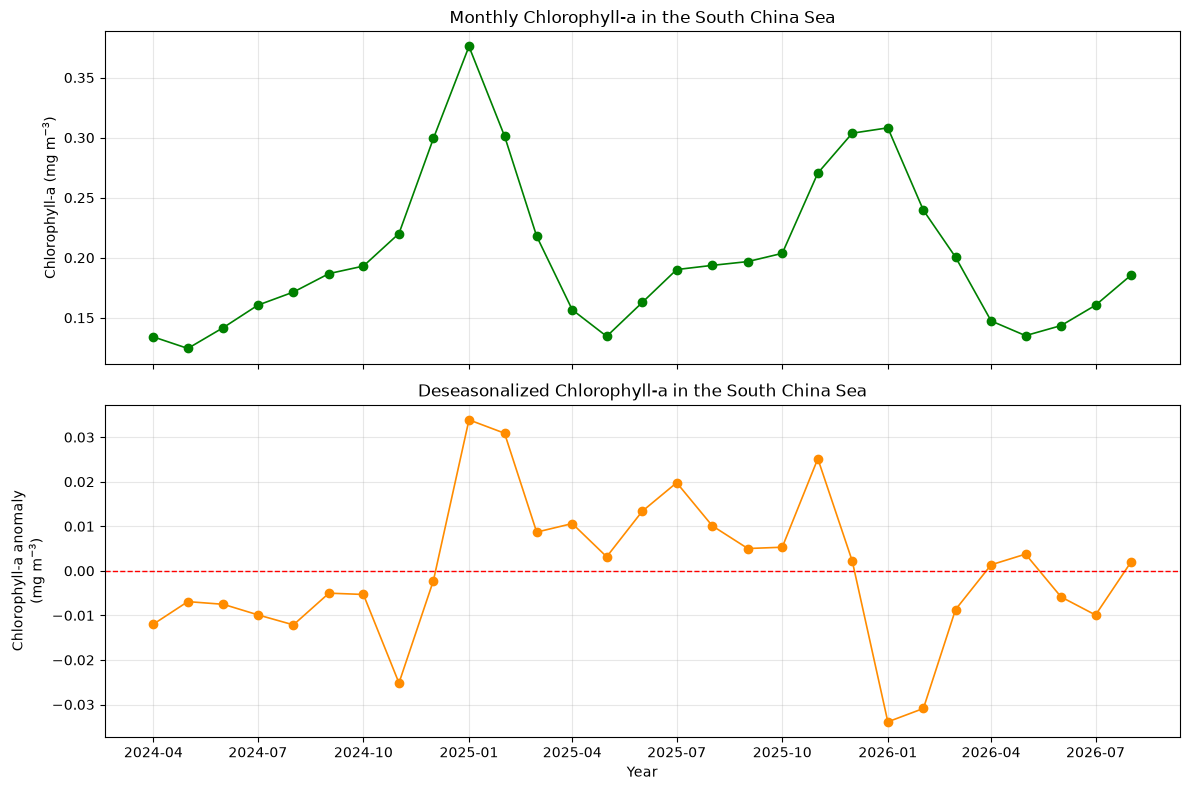

In [21]:
#3.1 绘制原始序列和去季节序列
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    chla_series.time,
    chla_series,
    color="green",
    marker="o",
    linewidth=1.2
)
axes[0].set_ylabel("Chlorophyll-a (mg m$^{-3}$)")
axes[0].set_title("Monthly Chlorophyll-a in the South China Sea")
axes[0].grid(alpha=0.3)

axes[1].plot(
    chla_anomaly.time,
    chla_anomaly,
    color="darkorange",
    marker="o",
    linewidth=1.2
)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Chlorophyll-a anomaly\n(mg m$^{-3}$)")
axes[1].set_title("Deseasonalized Chlorophyll-a in the South China Sea")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


C:\Users\Administrator\Documents\Codex\2026-11-11\assignment-03-out-10-28-19-3\work\python-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


C:\Users\Administrator\Documents\Codex\2026-11-11\assignment-03-out-10-28-19-3\work\python-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


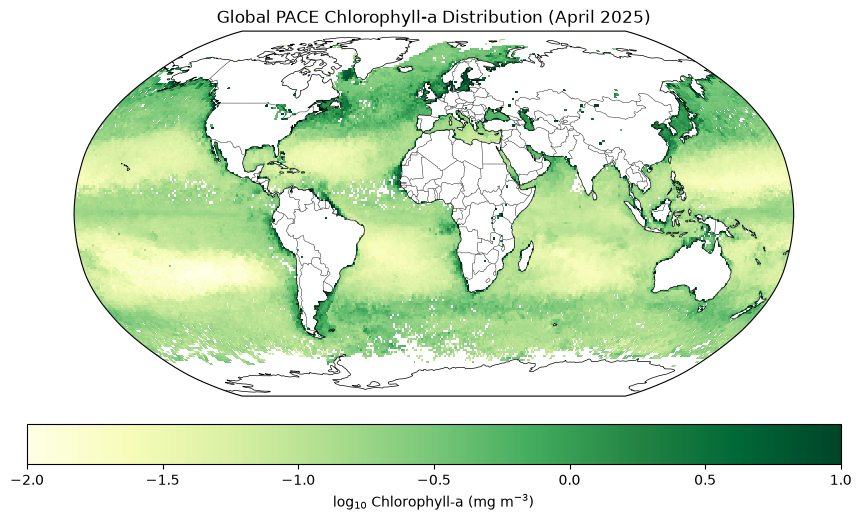

In [22]:
#3.2 图1：单月全球叶绿素空间分布
sample_chla = chla_maps.sel(time="2025-04", method="nearest")

fig, ax = plt.subplots(
    figsize=(14, 6),
    subplot_kw={"projection": ccrs.Robinson()}
)

im = ax.pcolormesh(
    sample_chla.lon,
    sample_chla.lat,
    np.log10(sample_chla),
    transform=ccrs.PlateCarree(),
    cmap="YlGn",
    vmin=-2,
    vmax=1,
    shading="auto"
)

ax.set_global()
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
cbar = plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.06, shrink=0.75)
cbar.set_label("log$_{10}$ Chlorophyll-a (mg m$^{-3}$)")
ax.set_title("Global PACE Chlorophyll-a Distribution (April 2025)")

plt.show()


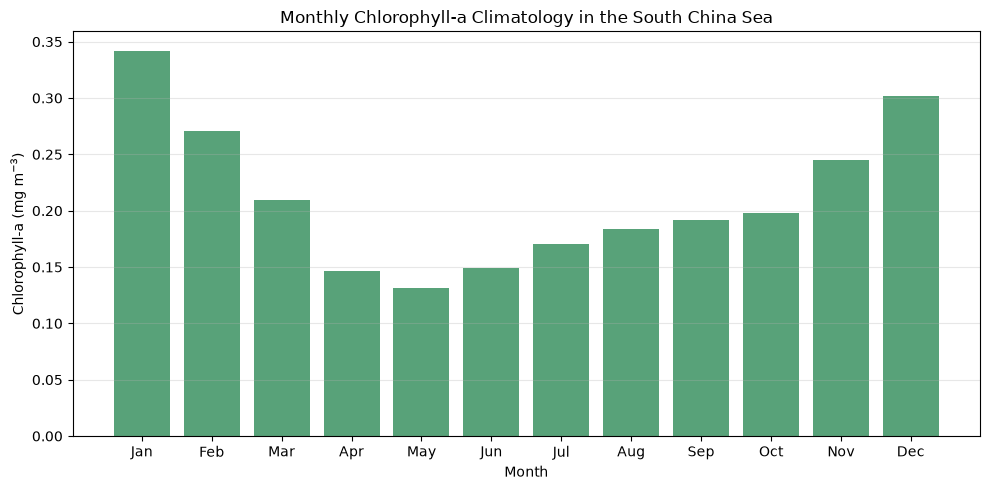

In [23]:
#3.2 图2：南海月气候态柱状图
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 5))
plt.bar(
    np.arange(1, 13),
    chla_climatology,
    color="seagreen",
    alpha=0.8
)
plt.xticks(np.arange(1, 13), month_names)
plt.xlabel("Month")
plt.ylabel("Chlorophyll-a (mg m$^{-3}$)")
plt.title("Monthly Chlorophyll-a Climatology in the South China Sea")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


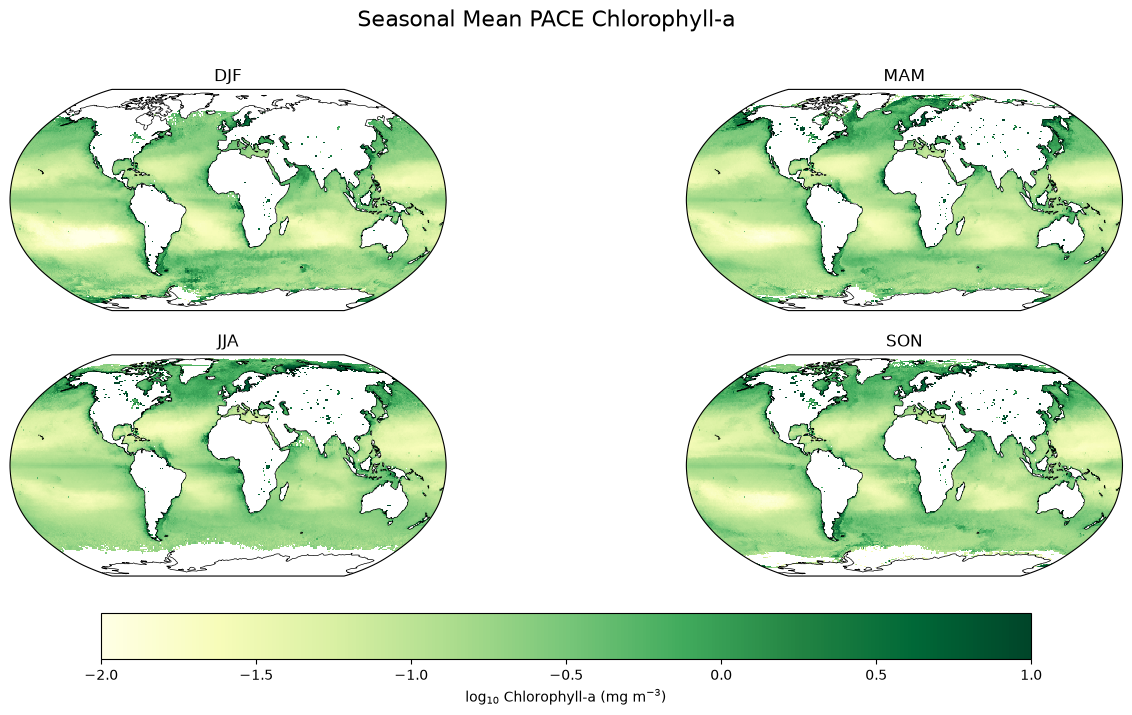

In [24]:
#3.2 图3：四季平均叶绿素空间分布
season_months = {
    "DJF": [12, 1, 2],
    "MAM": [3, 4, 5],
    "JJA": [6, 7, 8],
    "SON": [9, 10, 11]
}

fig, axes = plt.subplots(
    2, 2, figsize=(16, 8),
    subplot_kw={"projection": ccrs.Robinson()}
)

for ax, (season, months) in zip(axes.flat, season_months.items()):
    season_data = chla_maps.where(
        chla_maps.time.dt.month.isin(months),
        drop=True
    ).mean(dim="time", skipna=True)

    im = ax.pcolormesh(
        season_data.lon,
        season_data.lat,
        np.log10(season_data),
        transform=ccrs.PlateCarree(),
        cmap="YlGn",
        vmin=-2,
        vmax=1,
        shading="auto"
    )

    ax.set_global()
    ax.coastlines(linewidth=0.5)
    ax.set_title(season)

cbar = fig.colorbar(
    im, ax=axes.ravel().tolist(),
    orientation="horizontal", pad=0.06,
    shrink=0.75
)
cbar.set_label("log$_{10}$ Chlorophyll-a (mg m$^{-3}$)")
fig.suptitle("Seasonal Mean PACE Chlorophyll-a", fontsize=16)
plt.show()


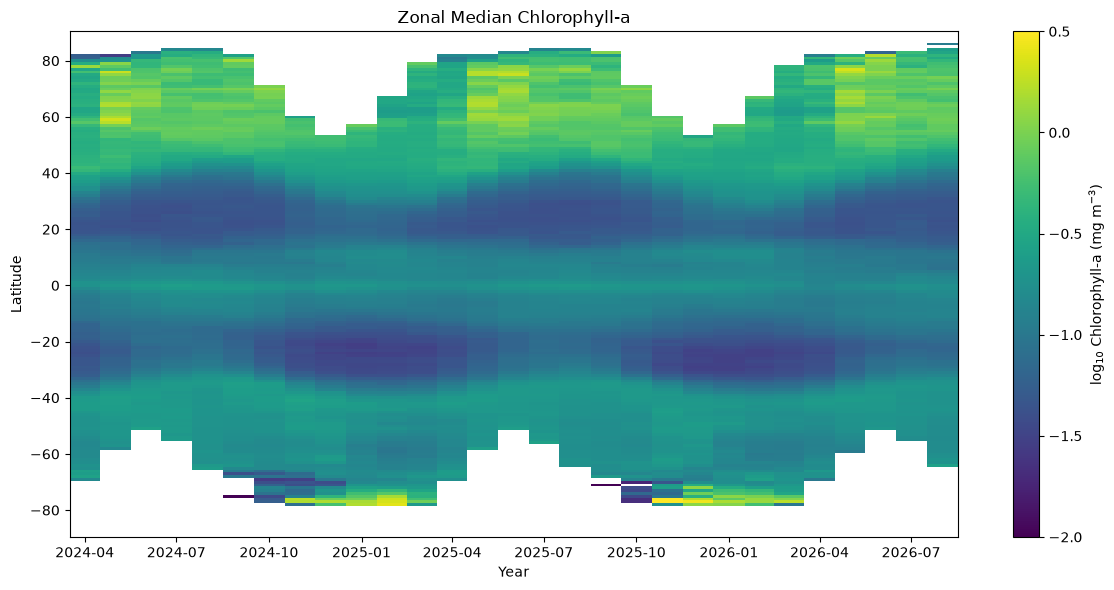

In [25]:
#3.2 图4：纬度-时间图
#对每个纬度的所有经度取中位数
zonal_chla = chla_maps.median(dim="lon", skipna=True)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(
    zonal_chla.time,
    zonal_chla.lat,
    np.log10(zonal_chla).transpose("lat", "time"),
    cmap="viridis",
    vmin=-2,
    vmax=0.5,
    shading="auto"
)

plt.colorbar(im, ax=ax, label="log$_{10}$ Chlorophyll-a (mg m$^{-3}$)")
ax.set_xlabel("Year")
ax.set_ylabel("Latitude")
ax.set_title("Zonal Median Chlorophyll-a")
plt.tight_layout()
plt.show()


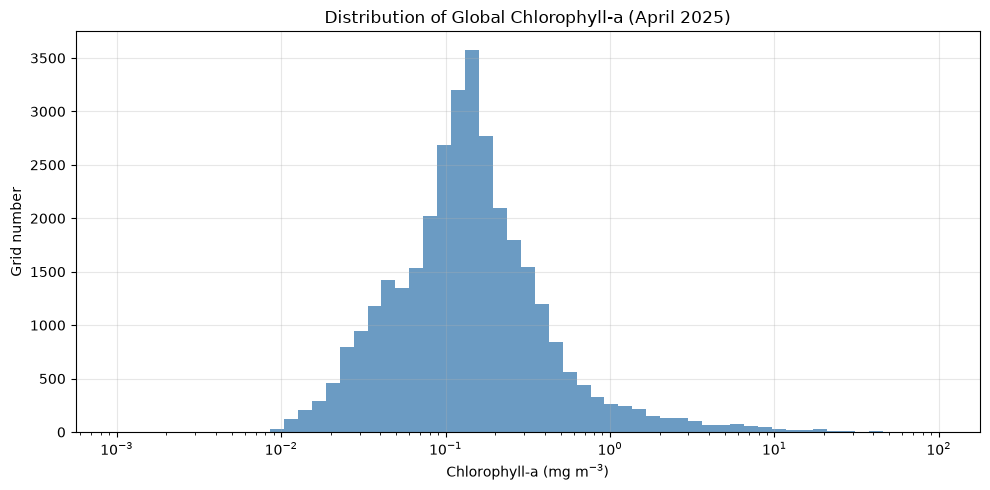

In [26]:
#3.2 图5：叶绿素浓度频率分布
chla_values = sample_chla.values.flatten()
chla_values = chla_values[np.isfinite(chla_values) & (chla_values > 0)]

plt.figure(figsize=(10, 5))
plt.hist(
    chla_values,
    bins=np.logspace(-3, 2, 60),
    color="steelblue",
    alpha=0.8
)
plt.xscale("log")
plt.xlabel("Chlorophyll-a (mg m$^{-3}$)")
plt.ylabel("Grid number")
plt.title("Distribution of Global Chlorophyll-a (April 2025)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
